# 🧱 Cell 1: 环境配置与路径定义 🛠️

# 首先导入所有必要的库，并定义好你的数据集路径。

In [8]:
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import *
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm

# 路径配置 (请确保这些目录已存在)
RAW_DATA_PATH = r"G:\WSLearning\Data"  # 原始图像根目录
FEATURE_PATH = r"G:\WSLearning\Data\features.vit"  # 存放提取后的特征文件 (.pt)
MODEL_SAVE_PATH = r"G:\WSLearning\best_mil_model.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"当前设备: {device} | 显存限制: 16G (请放心使用)")


当前设备: cuda | 显存限制: 16G (请放心使用)


# 🧱 Cell 2: 特征提取（核心：降维至 512 维） 🔍

# 这里我提供了 ResNet50 作为默认骨干，它最稳定。 

# 我们添加了一个 nn.Linear(2048, 512)  来强制降维。

# 运行建议： 这一步最耗时，建议先拿 2-3 个病人试运行。


## Vit的特征提取效果跟好

In [60]:
import os, torch, timm, numpy as np
from PIL import Image
from pathlib import Path
from tqdm import tqdm
from torchvision import transforms

RAW_PATCH_ROOT = r"G:\WSLearning\Data"
SAVE_ROOT = r"G:\WSLearning\Data\features.vit"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for s in ["train", "val"]:
    for l in ["High", "Low"]:
        os.makedirs(os.path.join(SAVE_ROOT, s, l), exist_ok=True)

# 加载 ViT（timm 支持 PyTorch 1.12）
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
model.to(DEVICE).eval()
print(f"✅ ViT-Base 加载成功，特征维度: 768")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

def extract(split, label):
    src = Path(RAW_PATCH_ROOT) / split / label
    dst = Path(SAVE_ROOT) / split / label
    
    patient_dirs = [d for d in src.iterdir() if d.is_dir()]
    print(f"\n{split}/{label}: {len(patient_dirs)} 个病人")
    
    for p_dir in tqdm(patient_dirs):
        save_path = dst / f"{p_dir.name}.pt"
        if save_path.exists(): continue
        
        patches = list(p_dir.glob("*.png")) + list(p_dir.glob("*.jpg"))
        if not patches: continue
        
        all_feats, all_coords = [], []
        for i in range(0, len(patches), 32):
            batch_paths = patches[i:i+32]
            imgs, coords = [], []
            for p in batch_paths:
                try:
                    imgs.append(transform(Image.open(p).convert('RGB')))
                    xy = p.stem.split('_')
                    coords.append([int(xy[0]), int(xy[1])])
                except: continue
            if not imgs: continue
            
            with torch.no_grad():
                feats = model(torch.stack(imgs).to(DEVICE)).cpu()
            all_feats.append(feats)
            all_coords.extend(coords)
        
        if all_feats:
            torch.save({
                'feats': torch.cat(all_feats).numpy(),
                'coords': np.array(all_coords),
                'label': 1 if label == "High" else 0
            }, save_path)

for s in ["train", "val"]:
    for l in ["High", "Low"]:
        extract(s, l)

print(f"\n✅ 提取完成！保存至: {SAVE_ROOT}")


'(MaxRetryError("HTTPSConnectionPool(host='huggingface.co', port=443): Max retries exceeded with url: /timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x0000024C8729D580>, 'Connection to huggingface.co timed out. (connect timeout=10)'))"), '(Request ID: 6b7d97cf-da7d-4a1d-8149-da387043e58b)')' thrown while requesting HEAD https://huggingface.co/timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'(MaxRetryError("HTTPSConnectionPool(host='huggingface.co', port=443): Max retries exceeded with url: /timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x0000024C8729D850>, 'Connection to huggingface.co timed out. (connect timeout=10)'))"), '(Request ID: e2100a65-33ef-4b13-a7c2-c71a3be46d22)')' thrown while requesting HEAD https:

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

C:\Users\niyuan\.conda\envs\deeppt\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\niyuan\.cache\huggingface\hub\models--timm--vit_base_patch16_224.augreg2_in21k_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


✅ ViT-Base 加载成功，特征维度: 768

train/High: 16 个病人


100%|██████████████████████████████████████████████████████████████████████████████████| 16/16 [10:50<00:00, 40.65s/it]



train/Low: 21 个病人


... (2 outputs left out)

100%|█████████████████████████████████████████████████████████████████████████████████| 15/15 [40:27<00:00, 161.83s/it]



val/Low: 20 个病人


100%|███████████████████████████████████████████████████████████████████████████████| 20/20 [1:08:17<00:00, 204.87s/it]


✅ 提取完成！保存至: G:\WSLearning\Data\features.vit


# ResNet50提取的模型，应该是不如VIT

In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet50'):
        super().__init__()
        if model_name == 'resnet50':
            base = models.resnet50(pretrained=True)
            self.backbone = nn.Sequential(*list(base.children())[:-1])
            in_features = 2048
        # 可选: 'vit_small' 或 'mobilenet_v3' (更省显存)
        
        self.fc = nn.Linear(in_features, 512) # 关键步：降维到 512

    def forward(self, x):
        with torch.no_grad():
            x = self.backbone(x)
            x = x.view(x.size(0), -1)
            return self.fc(x)

def run_extraction():
    extractor = FeatureExtractor().to(device).eval()
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    for split in ['train', 'val']:
        for label, class_val in [('High', 1), ('Low', 0)]:
            src_dir = Path(RAW_DATA_PATH) / split / label
            dst_dir = Path(FEATURE_PATH) / split / label
            dst_dir.mkdir(parents=True, exist_ok=True)

            for patient_path in src_dir.iterdir():
                if not patient_path.is_dir(): continue
                p_id = patient_path.name
                save_file = dst_dir / f"{p_id}.pt"
                if save_file.exists(): continue # 跳过已处理的

                images = list(patient_path.glob("*.png")) + list(patient_path.glob("*.jpg"))
                all_feats, all_coords = [], []

                for i in range(0, len(images), 32): # 16G显存 BatchSize设为32比较稳
                    batch_imgs = torch.stack([transform(Image.open(img).convert('RGB')) for img in images[i:i+32]]).to(device)
                    feats = extractor(batch_imgs).cpu().numpy()
                    all_feats.append(feats)
                    
                    # 解析坐标 (TCGA-A6-2684_..._x18623_y3826)
                    for img_p in images[i:i+32]:
                        parts = img_p.stem.split('_')
                        x = int(parts[-2][1:])
                        y = int(parts[-1][1:])
                        all_coords.append([x, y])
                
                torch.save({'feats': np.concatenate(all_feats), 'coords': np.array(all_coords), 'label': class_val}, save_file)
                print(f"已完成样本: {p_id}, 特征形状: {np.concatenate(all_feats).shape}")

run_extraction() # 取消注释以运行


# Attention-MIL 模型定义 🧠

# 这是多实例学习的核心。Attention 机制会学习每个 Patch 的权重。

In [11]:
os.chdir('G:\\WSLearning\\')

✅ 数据集加载完成: 52 个样本
✅ 数据集加载完成: 20 个样本
🔍 采样检查 -> 路径: TCGA-AA-A01V.pt | 标签: 1 (预期反向结果)
🚀 开始训练 Top-K 优化版 MIL 模型 (K=50)

🚨 标签可能反向！
Epoch [01/5] | Train Acc: 0.5769 | Val Acc: 0.4500
-------------------------------------------------------------
best_acc: 0.4500

🚨 标签可能反向！
Epoch [02/5] | Train Acc: 0.6923 | Val Acc: 0.5000
-------------------------------------------------------------
best_acc: 0.5000

🚨 标签可能反向！
Epoch [03/5] | Train Acc: 0.7692 | Val Acc: 0.5500
-------------------------------------------------------------
best_acc: 0.5500

🚨 标签可能反向！
Epoch [04/5] | Train Acc: 0.7692 | Val Acc: 0.6000
-------------------------------------------------------------
best_acc: 0.6000

🚨 标签可能反向！
Epoch [05/5] | Train Acc: 0.8077 | Val Acc: 0.6000


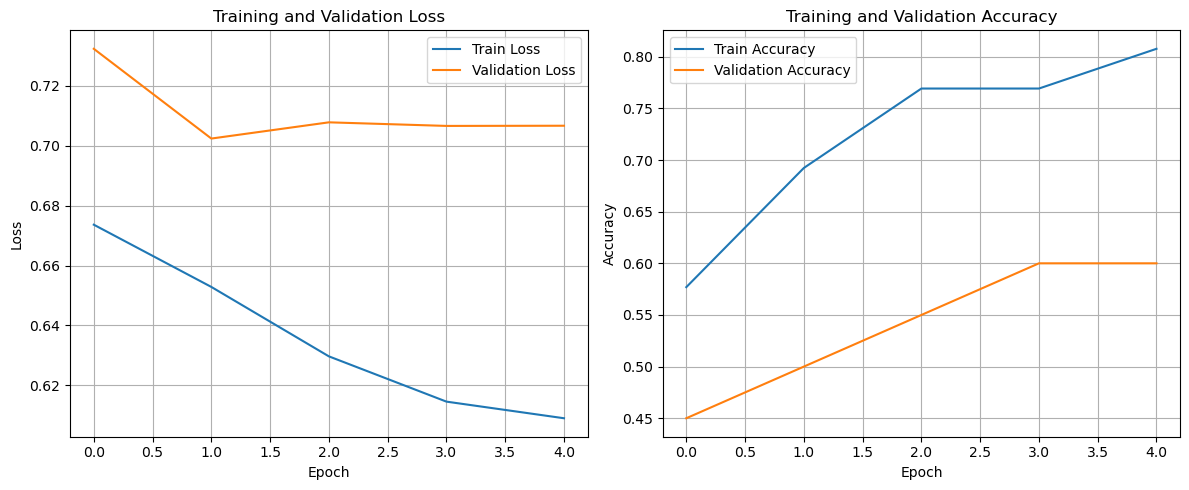

Highest Validation Accuracy: 0.600 at Epoch 4

🚨 标签可能反向！


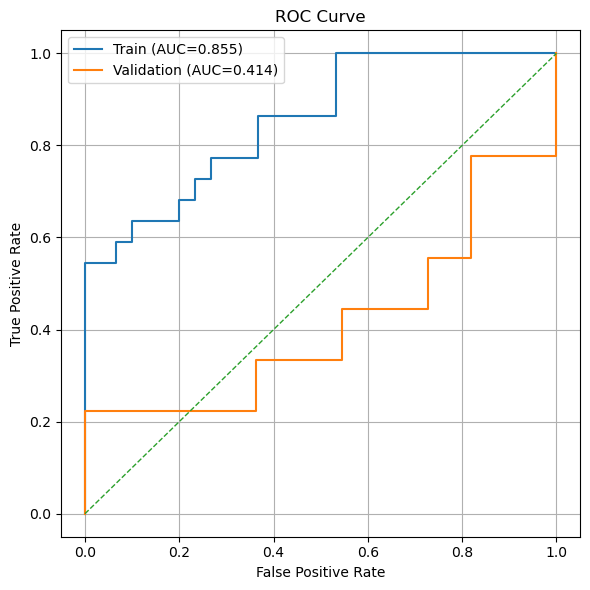

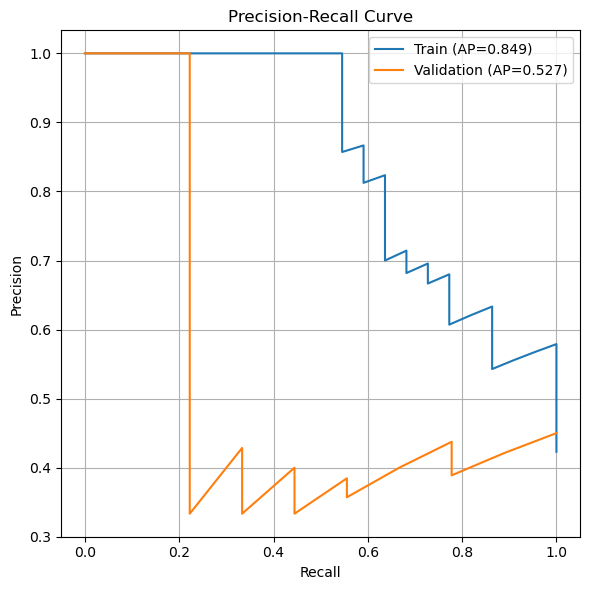

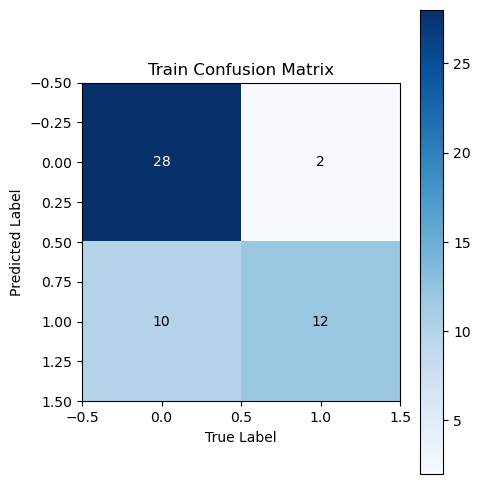

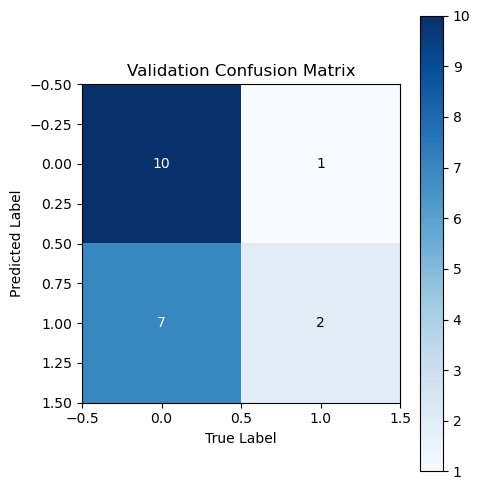

✅ 所有图像已保存为 PNG


In [12]:
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np
import torch
import torch.nn.functional as F

def evaluate(model, loader, criterion):
    model.eval()
    y_true, y_pred, y_probs = [], [], []
    total_loss = 0

    with torch.no_grad():
        for feats, label, _ in loader:
            feats = feats.squeeze(0).to(device)
            label = label.to(device)

            logits, _ = model(feats)
            loss = criterion(logits, label)
            total_loss += loss.item()

            probs = F.softmax(logits, dim=1)

            y_probs.append(probs.cpu().numpy()[0])
            y_true.append(label.item())
            y_pred.append(torch.argmax(logits).item())

    y_probs = np.array(y_probs)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    avg_loss = total_loss / len(loader)

    auc_normal = 0.5
    auc_flipped = 0.5

    if len(np.unique(y_true)) > 1:
        auc_normal = roc_auc_score(y_true, y_probs[:, 1])
        auc_flipped = roc_auc_score(y_true, y_probs[:, 0])

    if auc_flipped > auc_normal and auc_normal < 0.45:
        print("\n🚨 标签可能反向！")

    report = classification_report(
        y_true,
        y_pred,
        target_names=['Low', 'High'],
        output_dict=True,
        zero_division=0
    )

    return y_true, y_pred, y_probs, report, auc_normal, avg_loss

## MIL多层注意力定义函数

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

class TopK_GatedAttentionMIL(nn.Module):
    def __init__(self, feature_dim=768, hidden_dim=256, k=50):
        super(TopK_GatedAttentionMIL, self).__init__()
        self.k = k
        
        # 1. 特征预处理：LayerNorm 能显著稳定病理特征的分布
        self.feature_norm = nn.LayerNorm(feature_dim)
        
        # 2. 门控注意力机制 (Gated Attention)
        self.attention_V = nn.Sequential(nn.Linear(feature_dim, hidden_dim), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(feature_dim, hidden_dim), nn.Sigmoid())
        self.attention_weights = nn.Linear(hidden_dim, 1)

        # 3. 强力分类器 (增加 Dropout 强度防止过拟合)
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x):
        # x shape: [N, 512]
        x = self.feature_norm(x)
        
        # A. 计算所有 Patch 的原始注意力权重
        A_V = self.attention_V(x) # [N, hidden]
        A_U = self.attention_U(x) # [N, hidden]
        A = self.attention_weights(A_V * A_U) # [N, 1]
        A = torch.transpose(A, 1, 0)          # [1, N]
        
        # B. Top-K 过滤逻辑：只选取前 K 个最重要的 Patch
        if self.k < x.size(0):
            # 找到权重最高的 K 个位置
            topk_values, topk_indices = torch.topk(A, self.k, dim=1)
            # 仅对这 K 个 Patch 重新做 Softmax 归一化
            A_final = F.softmax(topk_values, dim=1) 
            # 提取对应的特征向量
            x_selected = x[topk_indices.squeeze()]
            # 聚合特征
            M = torch.mm(A_final, x_selected) 
        else:
            # 如果 Patch 总数不足 K，则按常规处理
            A_final = F.softmax(A, dim=1)
            M = torch.mm(A_final, x)
            
        logits = self.classifier(M)
        return logits, A_final


import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

class MILDataset(Dataset):
    def __init__(self, feature_root):
        self.files = list(Path(feature_root).resolve().rglob("*.pt"))
        print(f"✅ 数据集加载完成: {len(self.files)} 个样本")
        
    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        file_path = self.files[idx]
        data = torch.load(file_path)
        path_str = str(file_path).upper()
        
        # --- 【核心修改】：故意反向映射 ---
        # 如果路径包含 HIGH，标签设为 1
        # 如果路径包含 LOW， 标签设为 0
        if 'HIGH' in path_str:
            label = 1 
        else:
            label = 0
            
        return torch.from_numpy(data['feats']).float(), torch.tensor(label).long(), str(file_path)

# 实例化 DataLoader
train_loader = DataLoader(MILDataset(Path(FEATURE_PATH)/'train'), batch_size=1, shuffle=True)
val_loader = DataLoader(MILDataset(Path(FEATURE_PATH)/'val'), batch_size=1)

# 验证一下标签是否真的“反”过来了
f, l, p = val_loader.dataset[0]
print(f"🔍 采样检查 -> 路径: {Path(p).name} | 标签: {l.item()} (预期反向结果)")


# MIL多层注意力网络，小样本效果很差，不如单层面的ML

import matplotlib.pyplot as plt
import torch.nn as nn

def run_optimized_training(epochs=50, lr=5e-5):

    mil_model = TopK_GatedAttentionMIL(feature_dim=768, k=50).to(device)

    optimizer = torch.optim.AdamW(mil_model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_acc = 0

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    print("🚀 开始训练 Top-K 优化版 MIL 模型 (K=50)")

    for epoch in range(epochs):

        mil_model.train()
        train_loss = 0

        for feats, label, _ in train_loader:
            feats = feats.squeeze(0).to(device)
            label = label.to(device)

            if feats.size(0) > 100:
                idx = torch.randperm(feats.size(0))[:int(feats.size(0) * 0.7)]
                feats = feats[idx]

            optimizer.zero_grad()
            logits, _ = mil_model(feats)
            loss = criterion(logits, label)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        scheduler.step()

        # ===== 训练评估 =====
        train_true, train_pred, train_probs, train_report, train_auc, train_eval_loss = evaluate(
            mil_model, train_loader, criterion)

        # ===== 验证评估 =====
        val_true, val_pred, val_probs, val_report, val_auc, val_eval_loss = evaluate(
            mil_model, val_loader, criterion)

        train_losses.append(train_eval_loss)
        val_losses.append(val_eval_loss)
        train_accuracies.append(train_report['accuracy'])
        val_accuracies.append(val_report['accuracy'])

        print(f"Epoch [{epoch+1:02d}/{epochs}] | "
              f"Train Acc: {train_report['accuracy']:.4f} | "
              f"Val Acc: {val_report['accuracy']:.4f}")

        # ===== 保存最佳模型 =====
        if val_report['accuracy'] > best_acc:
            best_acc = val_report['accuracy']
            print("-------------------------------------------------------------")
            print(f"best_acc: {best_acc:.4f}")
            torch.save(mil_model.state_dict(), "best_mil_model.pth")

    # ================= 可视化 =================
    plt.figure(figsize=(12, 5))

    # Loss 曲线
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid()

    # Accuracy 曲线
    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label='Train Accuracy')
    plt.plot(val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.savefig('acc_and_loss.png')
    plt.show()

    # 打印最佳准确率
    max_val_accuracy = max(val_accuracies)
    max_val_accuracy_epoch = val_accuracies.index(max_val_accuracy) + 1

    print("Highest Validation Accuracy: {:.3f} at Epoch {}".format(
        max_val_accuracy, max_val_accuracy_epoch))

    return mil_model




from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, auc
import numpy as np
import matplotlib.pyplot as plt
import os


def plot_all_curves(model, train_loader, val_loader, criterion, save_dir="results"):

    os.makedirs(save_dir, exist_ok=True)

    def collect(loader):
        y_true, y_pred, y_probs, _, _, _ = evaluate(model, loader, criterion)
        return np.array(y_true), np.array(y_pred), np.array(y_probs[:, 1])

    train_true, train_pred, train_prob = collect(train_loader)
    val_true, val_pred, val_prob = collect(val_loader)

    # ================= ROC =================
    plt.figure(figsize=(6, 6))

    for name, y_t, y_p in [
        ("Train", train_true, train_prob),
        ("Validation", val_true, val_prob)
    ]:
        fpr, tpr, _ = roc_curve(y_t, y_p)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.savefig(f"{save_dir}/roc.png")
    plt.show()

    # ================= PR =================
    plt.figure(figsize=(6, 6))

    for name, y_t, y_p in [
        ("Train", train_true, train_prob),
        ("Validation", val_true, val_prob)
    ]:
        precision, recall, _ = precision_recall_curve(y_t, y_p)
        pr_auc = auc(recall, precision)
        plt.plot(recall, precision, label=f"{name} (AP={pr_auc:.3f})")

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.savefig(f"{save_dir}/pr.png")
    plt.show()

    # ================= Confusion Matrix =================
    def plot_confusion(cm, title, filename):
        plt.figure(figsize=(5, 5))
        plt.imshow(cm, cmap=plt.cm.Blues)
        plt.colorbar()
        plt.xlabel("True Label")
        plt.ylabel("Predicted Label")
        plt.title(title)

        thresh = cm.max() / 2
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                plt.text(j, i, int(cm[i, j]),
                         ha="center",
                         va="center",
                         color="white" if cm[i, j] > thresh else "black")

        plt.tight_layout()
        plt.savefig(f"{save_dir}/{filename}")
        plt.show()

    plot_confusion(confusion_matrix(train_true, train_pred),
                   "Train Confusion Matrix",
                   "train_confusion_matrix.png")

    plot_confusion(confusion_matrix(val_true, val_pred),
                   "Validation Confusion Matrix",
                   "val_confusion_matrix.png")

    print("✅ 所有图像已保存为 PNG")

# 1️⃣ 训练
run_optimized_training(epochs=5)

# 2️⃣ 加载最佳模型
mil_model = TopK_GatedAttentionMIL(feature_dim=768, k=50).to(device)
mil_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device))
mil_model.eval()

# 3️⃣ 定义损失
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

# 4️⃣ 画图
plot_all_curves(mil_model, train_loader, val_loader, criterion)

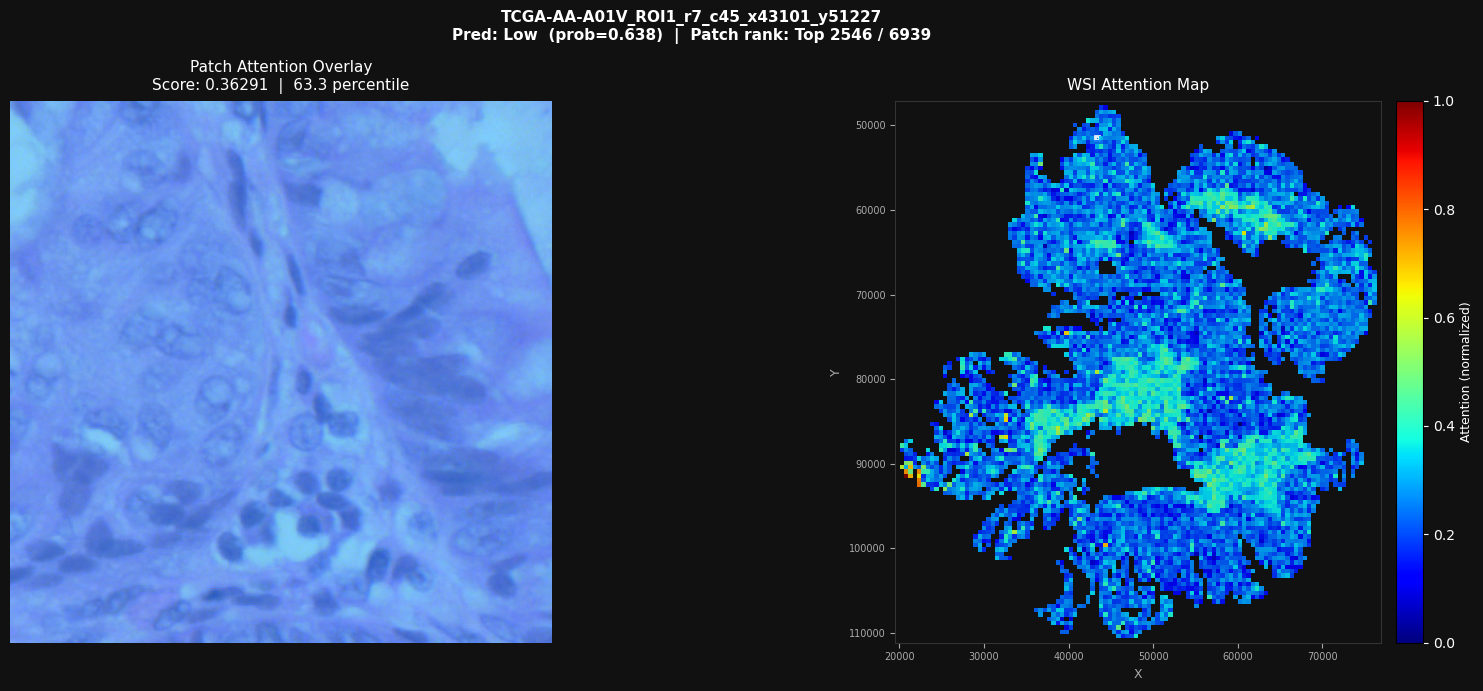

✅ 已保存: patch_vis/TCGA-AA-A01V_ROI1_r7_c45_x43101_y51227_vis.png


In [16]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from pathlib import Path
import re

def visualize_patch_and_wsi(
    model,
    png_path,
    feature_root,
    patch_root,
    save_dir="patch_vis",
    alpha_img=0.5,
    alpha_heat=0.5,
    patch_size=512       # WSI 中每个 patch 的实际像素尺寸
):
    png_path = Path(png_path)
    patient_dir  = png_path.parent
    patient_name = patient_dir.name
    stem         = png_path.stem

    match = re.search(r'_x(\d+)_y(\d+)', stem)
    assert match, f"❌ 找不到坐标: {stem}"
    patch_x = int(match.group(1))
    patch_y = int(match.group(2))

    rel_parts = patient_dir.relative_to(patch_root).parts
    split, label = rel_parts[0], rel_parts[1]
    pt_path = Path(feature_root) / split / label / f"{patient_name}.pt"

    data   = torch.load(pt_path, map_location='cpu')
    feats  = torch.from_numpy(data['feats']).float()
    coords = data['coords']
    N      = feats.shape[0]

    match_mask = (coords[:, 0] == patch_x) & (coords[:, 1] == patch_y)
    patch_idx  = int(np.where(match_mask)[0][0])

    model.eval()
    with torch.no_grad():
        logits, _ = model(feats.to(device))
        probs = F.softmax(logits, dim=1).squeeze()

        x_norm = model.feature_norm(feats.to(device))
        A_V    = model.attention_V(x_norm)
        A_U    = model.attention_U(x_norm)
        A_all  = model.attention_weights(A_V * A_U).squeeze()
        A_all  = torch.sigmoid(A_all).cpu().numpy()

    pred_class = torch.argmax(probs).item()
    pred_label = "High" if pred_class == 1 else "Low"
    pred_prob  = probs[pred_class].item()
    this_attn  = float(A_all[patch_idx])

    a_min, a_max = A_all.min(), A_all.max()
    attn_norm_global = (A_all - a_min) / (a_max - a_min + 1e-6)
    this_attn_norm   = float(attn_norm_global[patch_idx])
    percentile       = float((A_all < this_attn).mean() * 100)

    # ============================================================
    # 图1：单个 patch 热力图叠加
    # ============================================================
    img_bgr = cv2.imread(str(png_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    H, W    = img_rgb.shape[:2]

    cam_val  = np.uint8(255 * this_attn_norm)
    cam_flat = np.full((H, W), cam_val, dtype=np.uint8)
    heatmap  = cv2.applyColorMap(cam_flat, cv2.COLORMAP_JET)
    overlay  = cv2.addWeighted(img_bgr, alpha_img, heatmap, alpha_heat, 0)
    overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

    # ============================================================
    # 图2：WSI 全局坐标热图 —— 每个 patch 绘制为 patch_size 大小的方块
    # ============================================================
    cmap = plt.cm.jet
    norm = mcolors.Normalize(vmin=0, vmax=1)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    fig.patch.set_facecolor('#111111')

    # --- 左图：patch 热图叠加 ---
    axes[0].imshow(overlay_rgb)
    axes[0].set_title(
        f"Patch Attention Overlay\n"
        f"Score: {this_attn:.5f}  |  {percentile:.1f} percentile",
        color='white', fontsize=11, pad=8
    )
    axes[0].axis('off')
    border_color = cmap(this_attn_norm)
    for spine in axes[0].spines.values():
        spine.set_edgecolor(border_color)
        spine.set_linewidth(4)
        spine.set_visible(True)

    # --- 右图：方块热图 ---
    ax = axes[1]
    ax.set_facecolor('#111111')

    for i in range(N):
        x, y       = coords[i, 0], coords[i, 1]
        color      = cmap(norm(attn_norm_global[i]))
        # 高亮当前 patch 加白色描边
        is_current = (i == patch_idx)
        rect = mpatches.Rectangle(
            (x, y),                     # 左下角坐标
            patch_size, patch_size,     # 宽 × 高
            linewidth=2 if is_current else 0,
            edgecolor='white' if is_current else 'none',
            facecolor=color,
            alpha=0.9
        )
        ax.add_patch(rect)

    # 设置坐标轴范围
    ax.set_xlim(coords[:, 0].min() - patch_size,
                coords[:, 0].max() + patch_size * 2)
    ax.set_ylim(coords[:, 1].min() - patch_size,
                coords[:, 1].max() + patch_size * 2)
    ax.invert_yaxis()
    ax.set_aspect('equal')

    # colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label('Attention (normalized)', color='white', fontsize=9)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(cb.ax.yaxis.get_ticklabels(), color='white')

    ax.set_title("WSI Attention Map", color='white', fontsize=11, pad=8)
    ax.set_xlabel('X', color='#aaaaaa', fontsize=9)
    ax.set_ylabel('Y', color='#aaaaaa', fontsize=9)
    ax.tick_params(colors='#aaaaaa', labelsize=7)
    ax.spines[['top', 'right', 'left', 'bottom']].set_color('#333333')

    fig.suptitle(
        f"{stem}\n"
        f"Pred: {pred_label}  (prob={pred_prob:.3f})  |  "
        f"Patch rank: Top {int((A_all >= this_attn).sum())} / {N}",
        color='white', fontsize=11, fontweight='bold'
    )

    plt.tight_layout()
    Path(save_dir).mkdir(parents=True, exist_ok=True)
    out_path = f"{save_dir}/{stem}_vis.png"
    plt.savefig(out_path, dpi=150, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.show()
    print(f"✅ 已保存: {out_path}")


# 使用
visualize_patch_and_wsi(
    model        = mil_model,
    png_path     = r"G:\WSLearning\Data\val\High\TCGA-AA-A01V\TCGA-AA-A01V_ROI1_r7_c45_x43101_y51227.png",
    feature_root = r"G:\WSLearning\Data\features.vit",
    patch_root   = r"G:\WSLearning\Data",
    save_dir     = "patch_vis",
    patch_size   = 512
)